# AI 통계학 26~102페이지 연계 Python 실습

첨부 PPTX의 **26~102페이지**를 대상으로, 슬라이드에 제시된 이론과 39개 실습 항목을 연결함.

- 각 단원은 **이론 요약 → 실습 목표 → Python 코드 → 결과 해석** 순서로 구성함.
- 원래 PPTX 코드에서 정의되지 않은 변수는 공통 데이터 준비 셀로 보완함.
- 실제 파일 다운로드 없이 NumPy·Pandas·SciPy·scikit-learn 내장/가상 데이터로 실행 가능함.

설치: `pip install numpy pandas matplotlib seaborn scipy scikit-learn`


In [4]:
# 공통 실행 환경과 재현 가능한 데이터 준비
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, classification_report, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.datasets import make_classification

rng=np.random.default_rng(42)
sns.set_theme(style="whitegrid")
df=pd.DataFrame({
  "x":rng.normal(50,10,350),
  "sales":rng.lognormal(4,.6,350),
  "group":rng.choice(["A","B"],350),
  "ad":rng.normal(100,20,350),
  "visitors":rng.normal(300,60,350),
  "price":rng.normal(20,3,350)
})
df["target"]=(df["x"]+rng.normal(0,6,350)>50).astype(int)
df["revenue"]=20+1.5*df.ad+.8*df.visitors-2*df.price+rng.normal(0,30,350)
print("공통 데이터 크기:",df.shape)


공통 데이터 크기: (350, 8)


## 통계와 AI 실습 (PPTX 26페이지)

### 연결 이론: 통계와 AI (25페이지)

- 통계는 데이터의 중심·변동성·불확실성을 수치로 표현한다.
- AI는 데이터에서 패턴을 학습하므로 데이터 분포가 바뀌면 예측 성능도 달라질 수 있다.
- 기술통계는 데이터를 요약하고 추론통계는 표본으로 모집단을 판단한다.
- 평균 하나만으로는 데이터의 위험과 변동성을 충분히 설명할 수 없다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


평균: 10.0 10.0 표준편차: 1.4142135623730951 7.0710678118654755


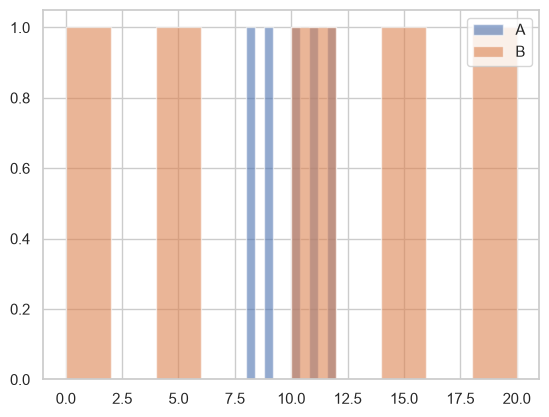

In [5]:
# PPTX 26페이지 연계 예제
A=np.array([8,9,10,11,12]); B=np.array([0,5,10,15,20])
print("평균:",A.mean(),B.mean(),"표준편차:",A.std(),B.std())
plt.hist(A,alpha=.6,label="A");plt.hist(B,alpha=.6,label="B");plt.legend();plt.show()


## 모집단과 표본 실습 (PPTX 28페이지)

### 연결 이론: 모집단과 표본 (27페이지)

- 모집단은 관심 대상 전체이며 표본은 모집단에서 관측한 일부다.
- 모수는 모집단의 특성이고 통계량은 표본에서 계산한 값이다.
- 표본평균은 표본을 다시 뽑을 때마다 달라질 수 있다.
- 표본 수가 커도 추출 방법이 편향되면 모집단을 제대로 대표하지 못한다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [6]:
# PPTX 28페이지 연계 예제
population=rng.normal(100,15,100000)
for n in [10,50,200]:
    means=[rng.choice(population,n,replace=False).mean() for _ in range(1000)]
    print("표본크기",n,"표본평균들의 평균",np.mean(means),"표준오차",np.std(means,ddof=1))


표본크기 10 표본평균들의 평균 99.87603169714639 표준오차 4.53966871108244
표본크기 50 표본평균들의 평균 99.97324933723439 표준오차 2.1743025743490834
표본크기 200 표본평균들의 평균 99.90965384098114 표준오차 1.0768801251857807


## 변수와 데이터 타입 실습 (PPTX 30페이지)

### 연결 이론: 변수와 데이터 타입 (29페이지)

- 수치형 변수는 연속형·이산형으로 구분한다.
- 범주형 변수는 명목형·순서형으로 구분한다.
- 날짜·시간은 순서와 주기 정보를 가진 별도의 분석 변수다.
- ID가 숫자로 저장돼도 일반적인 연속형 feature로 사용하면 안 된다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 30페이지 연계 예제
print(df.dtypes)
print("고유값 개수:",df.nunique().to_dict())
print("수치형:",df.select_dtypes(include="number").columns.tolist())


## 평균·중앙값·최빈값 실습 (PPTX 32페이지)

### 연결 이론: 평균·중앙값·최빈값 (31페이지)

- 평균은 모든 값을 반영하지만 극단값에 민감하다.
- 중앙값은 정렬된 자료의 가운데 값으로 치우친 분포에서 강건하다.
- 최빈값은 가장 자주 나타난 값이며 범주형 데이터에도 사용할 수 있다.
- 평균과 중앙값의 차이는 왜도와 이상치의 단서가 된다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [1]:
# PPTX 32페이지 연계 예제
x_skew=rng.lognormal(2.4,.65,1000)
print("평균",np.mean(x_skew),"중앙값",np.median(x_skew))
plt.hist(x_skew,bins=35);plt.axvline(np.mean(x_skew),color="red",ls="--",label="mean")
plt.axvline(np.median(x_skew),color="green",label="median");plt.legend();plt.show()


NameError: name 'rng' is not defined

## 분산·표준편차·IQR 실습 (PPTX 34페이지)

### 연결 이론: 분산·표준편차·IQR (33페이지)

- 분산은 평균으로부터의 제곱편차 평균으로 산포를 측정한다. 모집단 분산은 σ²=(1/N)Σ(xᵢ−μ)², 표본분산은 보통 s²=(1/(n−1))Σ(xᵢ−x̄)²를 사용한다.
- 표준편차는 분산의 제곱근이며 원래 변수와 같은 단위다.
- IQR은 Q3−Q1로 중앙 50%의 폭을 나타낸다.
- 동일 평균이라도 산포도가 다르면 공정·수요·센서의 안정성이 다를 수 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 34페이지 연계 예제
q1,q3=df["x"].quantile([.25,.75]);iqr=q3-q1
print(df["x"].describe(),"IQR",iqr)
plt.boxplot(df["x"].dropna(),vert=False);plt.show()


## 분포·왜도 실습 (PPTX 36페이지)

### 연결 이론: 분포·왜도 (35페이지)

- 히스토그램은 데이터의 분포 형태를 확인하는 기본 그래프다.
- 왜도는 분포가 좌우로 얼마나 비대칭인지 나타낸다.
- 오른쪽 꼬리가 길면 양의 왜도, 왼쪽 꼬리가 길면 음의 왜도를 갖는다.
- 분포를 확인하지 않고 평균만 보고하면 실제 데이터 특성을 놓칠 수 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 36페이지 연계 예제
print("왜도:",df["sales"].skew())
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].hist(df["sales"],bins=30);ax[0].set_title("Original")
ax[1].hist(np.log1p(df["sales"]),bins=30);ax[1].set_title("log1p")
plt.tight_layout();plt.show()


## 결측치·이상치 실습 (PPTX 38페이지)

### 연결 이론: 결측치·이상치 (37페이지)

- 결측치는 단순 누락일 수도 있고 특정 조건에서 발생한 구조적 정보일 수도 있다.
- IQR 방식은 이상치 후보를 찾는 규칙이지 자동 삭제 규칙이 아니다.
- 업무상 중요한 대형 고객도 통계적으로는 이상치일 수 있다.
- 결측·이상치 처리 전후 통계량과 모델 결과를 비교해야 한다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [7]:
# PPTX 38페이지 연계 예제
dirty=df.copy();dirty.loc[[2,8,22],"x"]=np.nan;dirty.loc[14,"x"]=130
print("결측률:",dirty.isna().mean().sort_values(ascending=False).head())
q1,q3=dirty.x.quantile([.25,.75]);iqr=q3-q1
out=dirty[(dirty.x<q1-1.5*iqr)|(dirty.x>q3+1.5*iqr)]
print("이상치 후보",len(out),"원평균",dirty.x.mean(),"후보 제외 평균",dirty.drop(out.index).x.mean())


결측률: x           0.008571
sales       0.000000
group       0.000000
ad          0.000000
visitors    0.000000
dtype: float64
이상치 후보 4 원평균 49.9999528170328 후보 제외 평균 49.523672276334


## EDA 실습 (PPTX 40페이지)

### 연결 이론: EDA (39페이지)

- EDA는 구조→품질→기술통계→분포→관계→가설의 순서로 수행한다.
- 관찰한 사실과 원인에 대한 추정을 구분한다.
- 그래프는 분석의 끝이 아니라 다음 질문을 만드는 도구다.
- EDA Notebook에는 코드·그래프·해석을 함께 기록해 재현성을 확보한다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 40페이지 연계 예제
print(df.describe(include="all").T.head())
print(df.groupby("group")["target"].agg(["mean","count"]))
sns.scatterplot(data=df,x="x",y="sales",hue="group",alpha=.6);plt.show()


## 확률 실습 (PPTX 42페이지)

### 연결 이론: 확률 (41페이지)

- 확률은 사건이 발생할 가능성을 0과 1 사이의 값으로 표현한다.
- 표본공간은 가능한 결과 전체, 사건은 관심 결과의 집합이다.
- 서로 배반과 독립은 서로 다른 개념이다.
- AI의 예측확률은 모델 출력이며 실제 장기 빈도와 일치하는지는 calibration으로 별도 확인할 수 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 42페이지 연계 예제
for n in [100,1000,10000]:
    trials=rng.binomial(1,.5,n)
    print(n,"앞면 비율",trials.mean())


## 조건부확률 실습 (PPTX 44페이지)

### 연결 이론: 조건부확률 (43페이지)

- 조건부확률 P(A|B)는 B가 주어진 상황에서 A의 확률이다.
- P(B)>0일 때 A와 B가 독립이면 P(A|B)=P(A)이다.
- 의료검사·불량검사·사기탐지에서는 기저율을 함께 고려해야 한다.
- Precision과 Recall도 조건부확률의 관점에서 이해할 수 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 44페이지 연계 예제
tab=pd.crosstab(df["group"],df["target"])
print(tab)
print(pd.crosstab(df.group,df.target,normalize="index"))


## 베이즈 정리 실습 (PPTX 46페이지)

### 연결 이론: 베이즈 정리 (45페이지)

- 베이즈 정리는 사전확률을 새로운 증거로 갱신한다.
- prior는 증거 관측 전의 확률 P(A), likelihood는 가설 A가 주어졌을 때 관측 증거 B의 확률 P(B|A)이다.
- posterior는 증거를 반영한 이후의 확률이다.
- 희귀 사건에서는 높은 검사 정확도만으로도 양성 예측의 신뢰도가 낮을 수 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 46페이지 연계 예제
prevalence=.01;sensitivity=.95;specificity=.95
p_pos=sensitivity*prevalence+(1-specificity)*(1-prevalence)
posterior=sensitivity*prevalence/p_pos
print("양성 후 실제 질병 확률:",round(posterior,4))


## 이항·포아송분포 실습 (PPTX 48페이지)

### 연결 이론: 이항·포아송분포 (47페이지)

- 이항분포는 성공확률 p가 각 시행에서 일정하고 시행들이 독립인 n회의 베르누이 시행에서 성공 횟수를 모델링한다.
- 이항분포의 기대값은 np, 분산은 np(1−p)다.
- 포아송분포는 일정 구간에서 사건이 평균 발생률 λ에 따라 독립적으로 발생한다는 모형에서 사건 횟수를 모델링하는 데 사용한다.
- 불량품 수·클릭 수·장애 건수 등에 적용할 수 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 48페이지 연계 예제
from scipy.stats import binom,poisson
print("100개 제품 중 불량 정확히 3개:",binom.pmf(3,100,.03))
print("시간당 평균 1.5건 중 정확히 2건:",poisson.pmf(2,1.5))


## 정규분포·z-score 실습 (PPTX 50페이지)

### 연결 이론: 정규분포·z-score (49페이지)

- 정규분포는 평균과 표준편차로 위치와 폭이 결정된다.
- z-score는 관측값이 평균에서 몇 표준편차 떨어졌는지 나타낸다.
- 표준화는 서로 다른 단위의 변수 비교에 유용하다.
- 모든 실제 데이터가 정규분포를 따르는 것은 아니다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 50페이지 연계 예제
from scipy.stats import norm,zscore
print("표준정규 ±1.96 확률",norm.cdf(1.96)-norm.cdf(-1.96))
z=zscore(df["x"].dropna())
print("최대 |z|",np.max(np.abs(z)))


## 중심극한정리 실습 (PPTX 52페이지)

### 연결 이론: 중심극한정리 (51페이지)

- 독립·동일분포이고 평균과 분산이 유한한 관측값을 가정하면, 원자료가 비정규여도 표본 크기가 커질수록 표본평균의 표준화된 분포는 정규분포에 가까워진다.
- 독립 표본에서 모집단 표준편차가 σ이면 표본평균의 표준편차(표준오차)는 σ/√n이다. σ를 모르면 보통 s/√n으로 추정한다.
- 중심극한정리는 신뢰구간과 많은 가설검정의 기반이다.
- 원자료 분포와 표본평균 분포를 혼동하지 않는다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 52페이지 연계 예제
population_exp=rng.exponential(1,100000)
for n in [5,30,100]:
    means=[rng.choice(population_exp,n).mean() for _ in range(1500)]
    plt.hist(means,bins=30,alpha=.45,label="n="+str(n),density=True)
plt.legend();plt.title("Sampling distributions");plt.show()


## 시뮬레이션 실습 (PPTX 54페이지)

### 연결 이론: 시뮬레이션 (53페이지)

- 시뮬레이션은 수학적 가정을 반복 실험으로 확인하는 방법이다.
- random seed를 고정하면 동일한 난수 흐름을 재현할 수 있다.
- 민감도 분석은 가정값을 바꿨을 때 결과가 얼마나 변하는지 확인한다.
- 시뮬레이션 결과는 설정한 확률모형의 결과이며 현실을 자동으로 보장하지 않는다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 54페이지 연계 예제
for prob in [.01,.03,.10]:
    counts=rng.binomial(100,prob,10000)
    print("p",prob,"평균",counts.mean(),"표준편차",counts.std())


## Naive Bayes 실습 (PPTX 56페이지)

### 연결 이론: Naive Bayes (55페이지)

- Naive Bayes는 베이즈 정리와 조건부 독립 가정을 이용하는 분류기다.
- 텍스트에서는 단어 빈도를 feature로 사용할 수 있다.
- 단순한 가정에도 빠르고 강한 baseline이 될 수 있다.
- 오분류 사례를 분석해 독립 가정과 표현 방식의 한계를 확인한다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 56페이지 연계 예제
texts=["good quality product","very bad item","excellent service","terrible defect",
       "good excellent item","bad defective product"]
sentiment=np.array([1,0,1,0,1,0])
vectorizer=CountVectorizer()
Xt=vectorizer.fit_transform(texts)
nb_model=MultinomialNB().fit(Xt,sentiment)
print("새 문장 예측:",nb_model.predict(vectorizer.transform(["excellent product"])))


## 표본분포·표준오차 실습 (PPTX 58페이지)

### 연결 이론: 표본분포·표준오차 (57페이지)

- 표본통계량은 표본이 달라지면 달라지는 확률변수다.
- 표본평균들의 분포를 표본분포라고 한다.
- 표준오차는 추정량이 표본마다 얼마나 흔들리는지 나타낸다.
- 표본 크기가 커지면 평균 추정의 표준오차가 감소하는 경향이 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 58페이지 연계 예제
for n in [10,30,100]:
    means=[rng.choice(population_exp,n).mean() for _ in range(1000)]
    print("n",n,"표본평균의 표준편차",np.std(means,ddof=1))


## 신뢰구간 실습 (PPTX 60페이지)

### 연결 이론: 신뢰구간 (59페이지)

- 신뢰구간은 표본으로부터 모수를 추정할 때 사용하는 구간추정 절차이며, 추정의 불확실성을 범위로 표현한다.
- 신뢰수준이 높아질수록 일반적으로 구간은 넓어진다.
- 표본 크기가 커질수록 같은 신뢰수준의 구간은 좁아지는 경향이 있다.
- 빈도주의 95% 신뢰구간은 반복 절차에서 약 95%의 구간이 참 모수를 포함한다는 의미다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 60페이지 연계 예제
for n in [20,100,500]:
    sample=rng.normal(100,15,n)
    ci=stats.t.interval(.95,n-1,loc=sample.mean(),scale=stats.sem(sample))
    print("n",n,"표본평균",round(sample.mean(),2),"95% CI",ci,"폭",ci[1]-ci[0])


## 가설검정·p-value 실습 (PPTX 62페이지)

### 연결 이론: 가설검정·p-value (61페이지)

- 귀무가설 H0와 대립가설 H1을 데이터 보기 전에 명확히 정의한다.
- p-value는 H₀와 검정의 가정이 참일 때, 선택한 검정통계량이 관측값만큼 또는 그보다 더 극단적인 값을 보일 확률이다.
- p-value는 H0가 참일 확률이 아니다.
- 통계적 유의성과 효과의 크기·실무 중요성은 서로 다르다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 62페이지 연계 예제
from scipy.stats import ttest_ind
for n in [20,100,1000]:
    a=rng.normal(0,1,n);b=rng.normal(.2,1,n)
    print("n",n,"평균차",b.mean()-a.mean(),"p",ttest_ind(a,b,equal_var=False).pvalue)


## t검정 실습 (PPTX 64페이지)

### 연결 이론: t검정 (63페이지)

- 독립표본 t검정은 서로 독립인 두 집단 평균을 비교한다.
- 대응표본 t검정은 동일 대상의 전후 측정처럼 짝지어진 자료에 사용한다.
- Welch t-test는 두 모집단 분산이 같다고 가정하지 않는 독립표본 평균 비교 t검정이다.
- 검정 선택은 데이터 구조와 실험설계에서 출발한다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 64페이지 연계 예제
from scipy.stats import ttest_ind,ttest_rel
group_a=rng.normal(100,12,45);group_b=rng.normal(104,13,45)
before=rng.normal(70,8,40);after=before+rng.normal(2,3,40)
print("Welch 독립표본",ttest_ind(group_a,group_b,equal_var=False))
print("대응표본",ttest_rel(before,after))


## 카이제곱검정 실습 (PPTX 66페이지)

### 연결 이론: 카이제곱검정 (65페이지)

- 카이제곱 독립성 검정은 두 범주형 변수의 연관성을 평가한다.
- 관측도수와 독립 가정 하의 기대도수를 비교한다.
- 유의한 결과는 연관성을 의미하지만 인과관계를 의미하지 않는다.
- 카이제곱 근사의 타당성을 위해 기대도수가 지나치게 작은 셀이 있는지 점검하며, 작은 표본의 2×2 표에서는 Fisher의 정확검정 등을 고려한다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 66페이지 연계 예제
table=np.array([[40,10],[25,25]])
chi2,p_value,dof,expected=stats.chi2_contingency(table)
print("카이제곱",chi2,"p",p_value,"기대도수",expected)


## ANOVA 실습 (PPTX 68페이지)

### 연결 이론: ANOVA (67페이지)

- ANOVA는 세 집단 이상 평균의 동일성을 한 번에 검정한다.
- 일원 ANOVA의 F 통계량은 집단 간 평균제곱 MS_between을 집단 내(오차) 평균제곱 MS_within으로 나눈 값이다.
- 유의한 일원 ANOVA 결과는 ‘모든 모집단 평균이 같다’는 귀무가설에 반하는 증거이며, 적어도 한 모집단 평균이 다름을 시사한다.
- 어느 집단이 다른지 확인하려면 사후분석을 고려한다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 68페이지 연계 예제
A=rng.normal(10,2,40);B=rng.normal(10,2,40);C=rng.normal(12,2,40)
print("일원분산분석:",stats.f_oneway(A,B,C))
plt.boxplot([A,B,C],tick_labels=["A","B","C"]);plt.show()


## A/B 테스트 실습 (PPTX 70페이지)

### 연결 이론: A/B 테스트 (69페이지)

- A/B 테스트는 변경안의 효과를 대조군과 비교하는 실험이다.
- 무작위 배정은 교란변수의 영향을 줄이는 핵심 설계 원칙이다.
- 주요 KPI·분석기간·표본수(검정력/유의수준/최소검출효과를 고려)와 분석 계획을 가능하면 사전에 정의한다.
- 통계적 유의성뿐 아니라 효과크기와 비용을 함께 판단한다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 70페이지 연계 예제
A=rng.binomial(1,.10,1000);B=rng.binomial(1,.12,1000)
delta=B.mean()-A.mean()
se=np.sqrt(A.mean()*(1-A.mean())/len(A)+B.mean()*(1-B.mean())/len(B))
print("A/B 전환율",A.mean(),B.mean(),"차이",delta,"근사 95% CI",(delta-1.96*se,delta+1.96*se))


## 통계검정 프로젝트 실습 (PPTX 72페이지)

### 연결 이론: 통계검정 프로젝트 (71페이지)

- 문제→가설→데이터→검정법→결과→효과크기→의사결정 순서로 보고한다.
- 검정법 선택 이유를 변수 타입과 실험설계에 연결한다.
- 결론에는 한계와 추가 실험 계획을 포함한다.
- 계산이 맞아도 해석이 틀리면 잘못된 의사결정이 된다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 72페이지 연계 예제
# 통계 프로젝트 미니 보고서
sample_a=rng.normal(50,5,60);sample_b=rng.normal(52,5,60)
result=stats.ttest_ind(sample_a,sample_b,equal_var=False)
print({"문제":"A/B 평균 차이","H0":"두 모평균 동일",
       "평균차":sample_b.mean()-sample_a.mean(),"p값":result.pvalue,
       "주의":"p값만으로 실무적 중요성을 판단하지 않음"})


## 상관관계 실습 (PPTX 74페이지)

### 연결 이론: 상관관계 (73페이지)

- 공분산은 두 변수가 함께 움직이는 방향을 나타낸다.
- Pearson 상관계수 r은 두 수치형 변수의 선형 연관성의 방향과 강도를 −1~1 범위로 요약한다.
- 상관계수 0은 모든 관계가 없다는 뜻이 아니다.
- 이상치가 상관계수에 큰 영향을 줄 수 있으므로 산점도를 함께 본다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 74페이지 연계 예제
x_corr=rng.normal(0,1,200);y_corr=.75*x_corr+rng.normal(0,.7,200)
print("Pearson r",np.corrcoef(x_corr,y_corr)[0,1])
plt.scatter(x_corr,y_corr,alpha=.6);plt.show()


## 상관과 인과 실습 (PPTX 76페이지)

### 연결 이론: 상관과 인과 (75페이지)

- 상관은 함께 변하는 패턴이고 인과는 한 변수 변화가 다른 변수 변화를 일으키는 관계다.
- 교란변수는 두 변수 모두에 영향을 주어 가짜 상관을 만들 수 있다.
- 역인과는 원인과 결과 방향을 반대로 해석하는 오류다.
- AI feature importance는 예측 기여도이지 인과효과가 아니다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 76페이지 연계 예제
z_group=rng.integers(0,2,400)
x_conf=z_group*3+rng.normal(0,1,400)
y_conf=z_group*3+rng.normal(0,1,400)
print("전체 상관",np.corrcoef(x_conf,y_conf)[0,1])
for group in [0,1]:
    print("그룹",group,"내 상관",np.corrcoef(x_conf[z_group==group],y_conf[z_group==group])[0,1])


## 선형회귀 실습 (PPTX 78페이지)

### 연결 이론: 선형회귀 (77페이지)

- 선형회귀는 입력과 출력의 평균적 선형관계를 모델링한다.
- 단순선형회귀에서 β₁은 모형이 적절하다는 가정 아래 x가 1단위 증가할 때 조건부 평균 E(Y|X=x)의 변화량이다.
- 최소제곱법은 잔차제곱합을 최소화하는 계수를 찾는다.
- 회귀계수의 해석은 변수 단위와 관측 범위 안에서 수행한다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 78페이지 연계 예제
x_reg=np.linspace(0,10,200)
y_reg=2+3*x_reg+rng.normal(0,3,200)
reg=LinearRegression().fit(x_reg.reshape(-1,1),y_reg)
print("절편",reg.intercept_,"기울기",reg.coef_[0])
plt.scatter(x_reg,y_reg,alpha=.3);plt.plot(x_reg,reg.predict(x_reg.reshape(-1,1)),color="red");plt.show()


## 다중회귀 실습 (PPTX 80페이지)

### 연결 이론: 다중회귀 (79페이지)

- 다중회귀는 여러 설명변수를 동시에 포함한다.
- 각 계수는 다른 포함 변수를 일정하게 둔 조건에서 해석한다.
- 설명변수끼리 높은 상관이 있으면 계수의 안정성이 떨어질 수 있다.
- 예측 목적과 설명 목적에 따라 변수 선택과 평가 관점이 달라진다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 80페이지 연계 예제
features=df[["ad","visitors","price"]];target_reg=df["revenue"]
Xtr,Xte,ytr,yte=train_test_split(features,target_reg,test_size=.25,random_state=42)
multi=LinearRegression().fit(Xtr,ytr)
print("회귀계수",dict(zip(features.columns,multi.coef_)),"test R²",multi.score(Xte,yte))
single=LinearRegression().fit(Xtr[["ad"]],ytr)
print("광고 하나만 쓴 회귀 test R²",single.score(Xte[["ad"]],yte))


## 잔차 실습 (PPTX 82페이지)

### 연결 이론: 잔차 (81페이지)

- 잔차는 실제값−예측값이다.
- 잔차에 체계적인 곡선 패턴이 남으면 모델이 관계를 충분히 설명하지 못할 수 있다.
- 예측값이 커질수록 잔차 분산이 커지면 등분산성 문제를 의심한다.
- 큰 잔차는 데이터 오류 또는 중요한 예외 사례일 수 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 82페이지 연계 예제
pred_reg=multi.predict(Xte)
residual=yte.to_numpy()-pred_reg
plt.scatter(pred_reg,residual);plt.axhline(0,color="red",ls="--")
plt.xlabel("Predicted");plt.ylabel("Residual");plt.show()
print("절대잔차 상위 5개 위치",np.argsort(np.abs(residual))[-5:])


## MAE·RMSE·R² 실습 (PPTX 84페이지)

### 연결 이론: MAE·RMSE·R² (83페이지)

- MAE는 절대오차 평균으로 원래 단위에서 직관적이다.
- RMSE는 큰 오차에 더 큰 가중을 주는 지표다.
- 표본 내 OLS에서 R²=1−SSE/SST는 평균 예측 대비 잔차제곱합 감소를 나타낸다. 별도 테스트 데이터에서 계산한 R²는 음수가 될 수도 있으므로 ‘설명된 비율’로 단순 해석하지 않는다.
- 업무 목적에 따라 어떤 종류의 오차가 더 중요한지 먼저 정한다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 84페이지 연계 예제
print("MAE",mean_absolute_error(yte,pred_reg))
print("RMSE",np.sqrt(mean_squared_error(yte,pred_reg)))
print("R²",r2_score(yte,pred_reg))
changed=pred_reg.copy();changed[0]+=100
print("큰 오류 추가 후 MAE/RMSE",mean_absolute_error(yte,changed),np.sqrt(mean_squared_error(yte,changed)))


## 과적합 실습 (PPTX 86페이지)

### 연결 이론: 과적합 (85페이지)

- 과적합은 훈련 데이터의 잡음까지 학습해 새로운 데이터에서 성능이 떨어지는 현상이다.
- 훈련 점수와 검증 점수의 큰 차이는 과적합의 신호가 될 수 있다.
- 모델 복잡도가 증가한다고 일반화 성능이 계속 좋아지는 것은 아니다.
- 교차검증은 모델 복잡도 선택에 유용하다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 86페이지 연계 예제
X_class,y_class=make_classification(n_samples=600,n_features=8,n_informative=4,
                                      n_redundant=0,random_state=42)
X_train,X_test,y_train,y_test=train_test_split(X_class,y_class,test_size=.25,random_state=42,stratify=y_class)
train_scores=[];test_scores=[]
for depth in range(1,16):
    model_tree=DecisionTreeClassifier(max_depth=depth,random_state=42).fit(X_train,y_train)
    train_scores.append(model_tree.score(X_train,y_train));test_scores.append(model_tree.score(X_test,y_test))
plt.plot(range(1,16),train_scores,label="train");plt.plot(range(1,16),test_scores,label="test")
plt.xlabel("max_depth");plt.legend();plt.show()


## 데이터 누수 실습 (PPTX 88페이지)

### 연결 이론: 데이터 누수 (87페이지)

- 데이터 누수는 예측 시점에 사용할 수 없는 정보가 학습 과정에 들어가는 문제다.
- 전처리 파라미터는 training data에서만 학습해야 한다.
- 일반적인 지도학습 평가에서는 test data를 이용해 전처리 파라미터나 모델 파라미터를 fit하지 않는다. 학습된 transformer의 transform만 적용한다.
- Pipeline은 전처리와 모델을 함께 묶어 교차검증 중 누수 가능성을 줄인다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 88페이지 연계 예제
# 학습/테스트 분리 후 파이프라인 안에서만 스케일링을 학습
pipe=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
pipe.fit(X_train,y_train)
print("Pipeline 테스트 정확도:",pipe.score(X_test,y_test))


## 분류와 임계값 실습 (PPTX 90페이지)

### 연결 이론: 분류와 임계값 (89페이지)

- 분류모델은 클래스 또는 클래스 확률을 예측한다.
- predict_proba의 확률을 임계값과 비교해 최종 클래스를 만들 수 있다.
- 임계값 0.5가 항상 최적은 아니다.
- 오류 비용에 따라 낮은 threshold는 recall을 높이고 FP를 늘릴 수 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 90페이지 연계 예제
clf=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000)).fit(X_train,y_train)
probability=clf.predict_proba(X_test)[:,1]
for threshold in [.3,.5,.7]:
    pred_class=(probability>=threshold).astype(int)
    print("임계값",threshold,"혼동행렬",confusion_matrix(y_test,pred_class).tolist())


## 혼동행렬 실습 (PPTX 92페이지)

### 연결 이론: 혼동행렬 (91페이지)

- TP와 TN은 올바른 예측, FP와 FN은 서로 다른 오류 유형이다.
- FP는 정상인데 양성으로 경보하는 오류다.
- FN은 실제 양성을 놓치는 오류다.
- 안전·의료·보안처럼 FN 비용이 큰 업무에서는 recall을 중요하게 볼 수 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 92페이지 연계 예제
pred_class=(probability>=.5).astype(int)
cm=confusion_matrix(y_test,pred_class)
tn,fp,fn,tp=cm.ravel()
print("TN/FP/FN/TP",tn,fp,fn,tp)
print(cm)


## Precision·Recall·F1 실습 (PPTX 94페이지)

### 연결 이론: Precision·Recall·F1 (93페이지)

- Precision은 양성 예측 중 실제 양성의 비율이다.
- Recall은 실제 양성 중 모델이 찾아낸 비율이다.
- F1은 Precision과 Recall의 조화평균이다.
- 불균형 데이터에서는 accuracy만으로 모델을 평가하면 소수 클래스를 놓칠 수 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 94페이지 연계 예제
for threshold in [.3,.5,.7]:
    pred_class=(probability>=threshold).astype(int)
    print(threshold,"Precision",precision_score(y_test,pred_class),
          "Recall",recall_score(y_test,pred_class),"F1",f1_score(y_test,pred_class))
print(classification_report(y_test,probability>=.5))


## ROC-AUC·PR 곡선·AP 실습 (PPTX 96페이지)

### 연결 이론: ROC-AUC·PR 곡선·AP (95페이지)

- ROC는 threshold 변화에 따른 TPR과 FPR을 표현한다.
- ROC-AUC는 양성과 음성을 순위로 구분하는 능력을 요약한다.
- 클래스 불균형이 심한 문제에서는 Precision-Recall 곡선과 Average Precision(AP)도 함께 확인하는 것이 유용하다.
- 높은 AUC가 특정 운영 threshold에서 좋은 결과를 자동 보장하지 않는다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 96페이지 연계 예제
print("ROC-AUC",roc_auc_score(y_test,probability))
print("Average Precision",average_precision_score(y_test,probability))
fig,ax=plt.subplots(1,2,figsize=(10,4))
RocCurveDisplay.from_predictions(y_test,probability,ax=ax[0])
PrecisionRecallDisplay.from_predictions(y_test,probability,ax=ax[1])
plt.tight_layout();plt.show()


## 교차검증 실습 (PPTX 98페이지)

### 연결 이론: 교차검증 (97페이지)

- 학습과 평가를 같은 데이터에서 수행하면 일반화 성능을 제대로 알 수 없다.
- k-fold CV는 k−1개 fold로 학습하고 남은 fold로 검증하는 과정을 반복한다.
- CV 평균은 선택한 분할에서의 평균 검증 성능을, fold 간 표준편차는 분할에 따른 점수 변동을 보여준다. 이를 일반화 오차의 엄밀한 신뢰구간으로 해석하지 않는다.
- 최종 test set은 모델 선택에 반복적으로 사용하지 않는다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 98페이지 연계 예제
scores=cross_val_score(clf,X_class,y_class,cv=5,scoring="f1")
print("5-fold F1",scores,"평균",scores.mean(),"표준편차",scores.std())


## Pipeline 실습 (PPTX 100페이지)

### 연결 이론: Pipeline (99페이지)

- Pipeline은 전처리 transformer와 최종 estimator를 순서대로 연결한다.
- Pipeline 전체를 fit하면 training data를 기준으로 전처리와 모델이 학습된다.
- 교차검증에서 각 fold별 전처리 fitting을 수행해 데이터 누수를 줄인다.
- Scaling·imputation·encoding·feature selection을 모델과 함께 관리할 수 있다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 100페이지 연계 예제
pipeline=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
print("Pipeline CV F1:",cross_val_score(pipeline,X_class,y_class,cv=cv,scoring="f1"))


## 모델 비교 실습 (PPTX 102페이지)

### 연결 이론: 모델 비교 (101페이지)

- 최고 평균 점수 하나만으로 모델을 선택하지 않는다.
- CV 변동성·오류 유형·해석 가능성·추론시간·유지비용을 함께 고려한다.
- 복잡한 모델의 작은 성능 향상이 운영 비용을 정당화하는지 검토한다.
- 모델 선정 이유를 평가 지표와 업무 목적에 연결해 문서화한다.

### 실습 목표
해당 개념을 계산·시각화하여 이론과 관측 결과를 비교함.

### 결과 해석 확인
출력 숫자와 그래프가 설명하는 통계적 의미 및 모델의 가정을 확인함.


In [ ]:
# PPTX 102페이지 연계 예제
models={"LogisticRegression":make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000)),
        "DecisionTree":DecisionTreeClassifier(max_depth=5,random_state=42)}
for name,model in models.items():
    scores=cross_val_score(model,X_class,y_class,cv=cv,scoring="f1")
    print(name,"평균 F1",scores.mean(),"표준편차",scores.std())


## 종합 과제

1. 기술통계와 추론통계 실습에서 표본 크기를 변경하고 결과를 비교함.
2. 분류 모델에서 임계값 변경에 따른 FP·FN과 Precision·Recall 변화를 기록함.
3. 회귀 모델에서 잔차 산점도와 MAE·RMSE·R²를 함께 보고함.
4. 최종 결과를 **문제 → 데이터 → 통계량/모델 → 평가 → 한계** 순서로 1페이지 보고서로 작성함.
